# Task 02 — Card-fraud scoring with traditional ML, done honestly

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Financial Transactions Dataset: Analytics](https://www.kaggle.com/datasets/computingvictor/transactions-fraud-datasets) (transactions + cards + users + MCC codes + fraud labels)
**Task family:** tabular supervised learning, imbalanced classification · **Companion task:** `01_aml_graph_triage.ipynb` (the graph counterpart)

---

## The task card

> **Board question.** *Our fraud team can review about 30 alerts a day. Can a scoring model cut fraud losses without declining good customers, and can we defend how it works to the regulator and to a customer whose card was blocked?*

**Business context.** A card issuer scores every transaction as it is authorised (Session 01's *online prediction* pattern) and routes a small number to analysts (*human-in-the-loop*). Three costs compete: fraud losses (the chargeback), analyst time, and the customer who is wrongly declined and moves their card to the back of the wallet. The model is one component in a legacy estate — the authorisation switch, the case-management tool, the chargeback process — and the architecture assessment in Milestone 1 must show where it plugs in.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **transaction-scoring model**, packaged and reproducible, evaluated *forward in time*, with the leakage traps in this notebook guarded by tests;
2. an **operating point chosen from costs and capacity**, not from a default 0.5 threshold, recorded as an ADR;
3. the **operational wrapper** the unit teaches: package, tests, CI gate, registered model, model card, monitoring plan with label delay handled explicitly;
4. a one-page **stakeholder recommendation** with a fairness check and the regulatory position.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Online scoring inside an authorisation flow; the four EA layers for a fraud system (the Session 01 worked example, now built); AI Act and GDPR position |
| 2 · MLOps | Temporal validation, quality gate on precision@k, drift and label delay (Session 04), registry + model card (Session 06) |
| 3 · Semantic layer | MCC codes and merchant hierarchy as a small ontology; "what is a *decline*?" across systems |
| 4 · LLM/RAG | Case notes for analysts; customer-facing explanation of a decline, grounded in the model's features (Session 10) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **synthetic** (an IBM-generated card-transaction corpus; the Kaggle packaging adds a users table, a cards table and a partial label file). The shapes are realistic — merchants, MCCs, chip vs swipe vs online, decline errors — but the fraud process is a simulator's, with artefacts listed in the dataset card.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | Features, training forward in time, the operating point, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The model after deployment, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the failure your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw` and `load_window` (Section 1); `build_features` (Section 3); `fit_eval` and `precision_at_k` (Section 4); `expected_cost` (Section 5); `psi` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 19 features; 773,262 training rows (1,537 fraud), 156,962 validation (652) and 932,762 test (2,448); capacity of 10,980 alerts over 366 days; AUPRC 0.781 on 2016, forward in time; threshold 0.05, giving 13 alerts a day and a cost of €20,161 against €90,058 without a model on validation.
- **Runtime:** about 5–6 minutes on a laptop (334 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.csv as pc
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "computingvictor/transactions-fraud-datasets"
WINDOW_START, WINDOW_END = pd.Timestamp("2015-01-01"), pd.Timestamp("2019-01-01")
TRAIN_END = pd.Timestamp("2015-11-01")   # train: Jan–Oct 2015
VALID_END = pd.Timestamp("2016-01-01")   # validation (threshold choice): Nov–Dec 2015
TEST_END = pd.Timestamp("2017-01-01")    # test: 2016 · production stream: 2017–2018 (labels arrive late)
ANALYST_CAPACITY_PER_DAY = 30            # alerts the fraud team can review per day (the portfolio is ~1,200 clients)
REVIEW_COST_EUR = 3.0                    # analyst minutes per alert, costed
FALSE_DECLINE_COST_EUR = 15.0            # goodwill cost of blocking a legitimate payment (assumption — see task C3)

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · numpy {np.__version__}")

pandas 3.0.5 · lightgbm 4.7.0 · numpy 2.5.3


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw` and `load_window`.*

| Field | Value |
|---|---|
| **Source** | Kaggle: `computingvictor/transactions-fraud-datasets` (packaging of an IBM synthetic card-transaction corpus) |
| **Licence** | Apache-2.0 |
| **Provenance** | Synthetic. Transactions, cards and users are generated; no real customers. The fraud labels are supplied for a random 67 % of transactions (`train_fraud_labels.json`); the remaining 33 % are unlabelled |
| **Size** | 13.3 M transactions, Jan 2010 – Oct 2019; 1,219 transacting clients (2,000 in the users table), 4,071 cards (6,146 in the cards table), 74,831 merchants, 109 MCC codes |
| **Files** | `transactions_data.csv` (1.26 GB), `train_fraud_labels.json` (159 MB), `cards_data.csv`, `users_data.csv`, `mcc_codes.json` |
| **Schema (transactions)** | `id`, `date`, `client_id`, `card_id`, `amount` (string with `$`, negatives are refunds), `use_chip` (Swipe / Chip / Online), `merchant_id`, `merchant_city`, `merchant_state`, `zip`, `mcc`, `errors` |
| **Label** | `is_fraud` ∈ {Yes, No} for labelled rows; 13,332 fraud among 8.9 M labelled (0.15 %); 2015: 2,189 · 2016: 2,448 · 2017: 172 · 2018: 1,629 |
| **Window used here** | Jan 2015 – Dec 2018: 5.57 M rows (≈ 0.8 GB in memory; ≈ 2.5 GB with features — shrink `WINDOW_END` on a small laptop). Train/validate on 2015, test on 2016, then treat 2017–2018 as the production stream |
| **PII** | `cards_data.csv` carries synthetic **card numbers, CVVs and expiry dates**; `users_data.csv` carries address, coordinates, gender, income, debt and credit score. Synthetic or not, we drop the card secrets on load and treat the user attributes as sensitive |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **The fraud *mechanism* changes by year.** 2010–2016: 85–90 % of fraud is *online* (online fraud rate ≈ 2 %). 2017–2019: online fraud disappears and almost every fraud is a chip transaction at a merchant in **Rome, Italy** (`merchant_state == "Italy"` is ≈ 88 % fraud in 2018). Volumes swing too: 0.31 % in 2010, 0.004 % in 2011, 0.018 % in 2017. No real portfolio behaves like this, but it is a gift for teaching: it makes drift, label delay and "the perfect feature" visible within one dataset.
2. **33 % of rows have no label.** The packaging calls them a test set; we treat them as the **production stream** — transactions you must score today and will only learn the truth about weeks later (*label delay*, Session 04).
3. **Negative amounts are refunds and credits** (~5 % of rows). They are legitimate activity, not errors, and they are informative.
4. **`errors` is a real-time signal** ("Bad PIN", "Insufficient Balance", "Bad CVV" …) known at authorisation time, so it is a fair feature. Other columns are not: see the trap section.
5. **The static tables have no timestamps.** `card_on_dark_web`, `credit_score`, `yearly_income` are snapshots of unknown date. A feature with no *as-of* time is a leak until proven otherwise.
6. **Only 1,219 clients.** Many client-level attributes act as a client identifier; a model can memorise *who* has fraud instead of *what* fraud looks like.

In [2]:
def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def load_window() -> pd.DataFrame:
    cache = PROCESSED / "fraud_2015_2018.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    t = time.time()
    convert = pc.ConvertOptions(column_types={"zip": pa.string(), "mcc": pa.string(), "errors": pa.string(),
                                              "amount": pa.string(), "merchant_state": pa.string()},
                                auto_dict_encode=True)
    tx = pc.read_csv(get_raw("transactions_data.csv"), convert_options=convert).to_pandas()
    tx["date"] = pd.to_datetime(tx["date"])
    tx["amount"] = tx["amount"].astype(str).str.replace("$", "", regex=False).astype(float)
    labels = pd.Series(json.load(open(get_raw("train_fraud_labels.json")))["target"])
    labels.index = labels.index.astype("int64")
    tx["is_fraud"] = tx["id"].map(labels).map({"Yes": 1, "No": 0}).astype("Int8")   # <NA> = unlabelled
    tx = tx[(tx.date >= WINDOW_START) & (tx.date < WINDOW_END)].sort_values(["card_id", "date"]).reset_index(drop=True)
    for c in ["use_chip", "merchant_city", "merchant_state", "mcc", "errors"]:
        tx[c] = tx[c].astype(str).replace({"None": "", "nan": ""})
    tx.to_parquet(cache)
    print(f"loaded + cached in {time.time()-t:.0f}s")
    return tx

tx = load_window()
cards = pd.read_csv(get_raw("cards_data.csv")).set_index("id")
users = pd.read_csv(get_raw("users_data.csv")).set_index("id")
mcc_names = json.load(open(get_raw("mcc_codes.json")))

# ---- governance habit: drop secrets on load, before anything else touches them ----
cards = cards.drop(columns=["card_number", "cvv", "expires"])
users = users.drop(columns=["address", "latitude", "longitude"])
for c in ["credit_limit"]:
    cards[c] = cards[c].str.replace("$", "", regex=False).astype(float)
for c in ["per_capita_income", "yearly_income", "total_debt"]:
    users[c] = users[c].str.replace("$", "", regex=False).astype(float)

print(f"{len(tx):,} transactions · {tx.is_fraud.notna().sum():,} labelled · {int(tx.is_fraud.sum()):,} fraud "
      f"({tx.is_fraud.mean():.2%} of labelled) · {tx.client_id.nunique():,} clients · {tx.card_id.nunique():,} cards · "
      f"{tx.memory_usage(deep=True).sum()/1e6:.0f} MB")
tx.head(3)

5,574,282 transactions · 3,734,869 labelled · 6,438 fraud (0.17% of labelled) · 1,214 clients · 3,711 cards · 753 MB


,id,date,client_id,card_id,amount,use_chip,merchant_id,merchant_city,merchant_state,zip,mcc,errors,is_fraud
0,15473157,2015-01-01 11:20:00,1362,0,17.40,Swipe Transaction,88646,Burke,VA,22015.0,5812,,0
1,15473403,2015-01-01 11:58:00,1362,0,16.16,Chip Transaction,10792,Burke,VA,22015.0,5411,,<NA>
2,15477680,2015-01-02 11:15:00,1362,0,17.73,Chip Transaction,45926,Burke,VA,22015.0,5814,,0


## 2 · First look

*Part A · Explore · read; the 2017 regime change it shows is the drift you will monitor.*

What a fraud analyst asks first: *how much* fraud, *when*, *through which channel*, and *what does the authorisation system already know* when it happens.

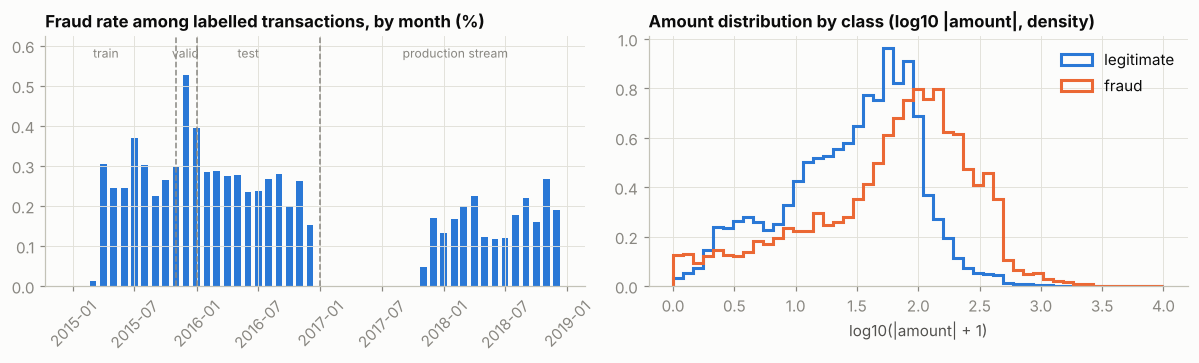

In [3]:
lab = tx[tx.is_fraud.notna()].copy()
lab["month"] = lab.date.dt.to_period("M")
monthly = lab.groupby("month").agg(n=("id", "size"), fraud=("is_fraud", "sum"))
monthly["rate"] = monthly.fraud / monthly.n

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
ax.bar(monthly.index.to_timestamp(), monthly.rate * 100, width=20, color=SERIES[0])
for x in [TRAIN_END, VALID_END, TEST_END]:
    ax.axvline(x, color=MUTED, ls="--", lw=1)
ymax = monthly.rate.max() * 100
ax.set_ylim(0, ymax * 1.18)
for x, lab_ in [("2015-03-01", "train"), ("2015-10-20", "valid"), ("2016-05-01", "test"), ("2017-09-01", "production stream")]:
    ax.text(pd.Timestamp(x), ymax * 1.08, lab_, color=MUTED, fontsize=8)
ax.set_title("Fraud rate among labelled transactions, by month (%)"); ax.tick_params(axis="x", rotation=45)

ax = axes[1]
bins = np.linspace(0, 4, 50)
for v, lab_, color in [(0, "legitimate", SERIES[0]), (1, "fraud", SERIES[1])]:
    a = np.log10(lab.loc[lab.is_fraud == v, "amount"].abs() + 1)
    ax.hist(a, bins=bins, density=True, histtype="step", lw=2, color=color, label=lab_)
ax.set_title("Amount distribution by class (log10 |amount|, density)"); ax.set_xlabel("log10(|amount| + 1)"); ax.legend()
plt.tight_layout()

In [4]:
def rate_table(col, top=None, min_n=500):
    t = lab.groupby(col).agg(n=("id", "size"), fraud=("is_fraud", "sum")).assign(rate=lambda d: d.fraud / d.n)
    t = t[t.n >= min_n].sort_values("rate", ascending=False)
    return t.head(top) if top else t

chip = rate_table("use_chip")
err = rate_table("errors")
mcc_t = rate_table("mcc", top=8); mcc_t.index = [f"{m} · {mcc_names.get(m, '?')[:34]}" for m in mcc_t.index]
print("by channel"); display(chip.style.format({"n": "{:,}", "fraud": "{:,}", "rate": "{:.2%}"}))
print("by authorisation error (n ≥ 500)"); display(err.style.format({"n": "{:,}", "fraud": "{:,}", "rate": "{:.2%}"}))
print("merchant categories with the highest fraud rate"); display(mcc_t.style.format({"n": "{:,}", "fraud": "{:,}", "rate": "{:.2%}"}))

by channel


,n,fraud,rate
use_chip,,,
Online Transaction,"454,213","4,045",0.89%
Chip Transaction,"2,650,871","1,938",0.07%
Swipe Transaction,"629,785",455,0.07%


by authorisation error (n ≥ 500)


,n,fraud,rate
errors,,,
Bad CVV,"1,783",63,3.53%
Bad Expiration,"1,752",31,1.77%
Bad Card Number,"2,260",28,1.24%
Bad PIN,"9,058",59,0.65%
Insufficient Balance,"36,552",83,0.23%
Technical Glitch,"7,531",13,0.17%
,"3,675,346","6,158",0.17%


merchant categories with the highest fraud rate


,n,fraud,rate
"5045 · Computers, Computer Peripheral Equ",783,89,11.37%
5732 · Electronics Stores,"2,037",190,9.33%
5094 · Precious Stones and Metals,"1,505",131,8.70%
4112 · Passenger Railways,630,46,7.30%
"5712 · Furniture, Home Furnishings, and E","1,067",72,6.75%
5816 · Digital Goods - Games,773,44,5.69%
5932 · Antique Shops,"1,649",54,3.27%
4511 · Airlines,808,23,2.85%


In [5]:
# The regime change, in one table: where fraud happens, by year
lab["year"] = lab.date.dt.year
lab["online"] = lab.use_chip == "Online Transaction"
lab["foreign_merchant"] = ~lab.merchant_state.isin([""] + [s for s in lab.merchant_state.unique() if len(s) == 2])
regime = lab.groupby("year").apply(lambda d: pd.Series({
    "fraud": int(d.is_fraud.sum()),
    "fraud rate": d.is_fraud.mean(),
    "share of fraud that is online": d.loc[d.is_fraud == 1, "online"].mean(),
    "share of fraud at a foreign merchant": d.loc[d.is_fraud == 1, "foreign_merchant"].mean(),
    "fraud rate · online": d.loc[d.online, "is_fraud"].mean(),
    "fraud rate · foreign merchant": d.loc[d.foreign_merchant, "is_fraud"].mean(),
}), include_groups=False)
regime.style.format({"fraud": "{:,}", "fraud rate": "{:.3%}", "share of fraud that is online": "{:.0%}",
                     "share of fraud at a foreign merchant": "{:.0%}", "fraud rate · online": "{:.2%}",
                     "fraud rate · foreign merchant": "{:.1%}"})

,fraud,fraud rate,share of fraud that is online,share of fraud at a foreign merchant,fraud rate · online,fraud rate · foreign merchant
year,,,,,,
2015,"2,189.0",0.235%,85%,0%,1.64%,0.0%
2016,"2,448.0",0.262%,86%,0%,1.84%,0.0%
2017,172.0,0.018%,0%,100%,0.00%,2.8%
2018,"1,629.0",0.174%,5%,94%,0.08%,22.7%


Read the regime table twice. In 2015–2016 fraud is an *online* phenomenon and a foreign merchant is barely a signal. From 2017 the simulator switches: online fraud vanishes, and a transaction at a foreign merchant (in practice: Rome) is fraud six times out of ten. A model trained in 2015 does not know this. Keep that in mind for Section 7.

In the training years, online transactions carry most of the risk; a *Bad PIN* at authorisation is a real-time signal; and a handful of merchant categories concentrate the fraud. All of this is known at the moment of authorisation — which is the test every feature below must pass.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · Features: what the authorisation switch knows *at that moment*

*Part B · Given model · package `build_features` unchanged; C1 turns the as-of rule into a test.*

Two families, with one rule for both: **a feature may only use information available before the transaction's timestamp.**

- **Base** — the transaction itself and the card's static type.
- **Velocity** — the card's own recent history: time since its previous transaction, how many in the last 24 h, how many ever, whether this merchant is new for this client, and how the amount compares with the card's past. These are the features a real-time feature store serves (Session 06 names it; Session 04 monitors it).

In [6]:
def build_features(tx: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=tx.index)
    # ---- base ----
    X["amount"] = tx.amount
    X["log_abs_amount"] = np.log1p(tx.amount.abs())
    X["is_refund"] = (tx.amount < 0).astype(int)
    X["hour"] = tx.date.dt.hour
    X["dow"] = tx.date.dt.dayofweek
    X["use_chip"] = tx.use_chip.astype("category")
    X["mcc"] = tx.mcc.astype("category")
    X["errors"] = tx.errors.replace("", "none").astype("category")
    X["has_error"] = (X.errors != "none").astype(int)
    X["merchant_state"] = tx.merchant_state.replace("", "online/none").astype("category")
    X["card_type"] = tx.card_id.map(cards.card_type).astype("category")
    X["card_brand"] = tx.card_id.map(cards.card_brand).astype("category")
    X["has_chip"] = tx.card_id.map(cards.has_chip).map({"YES": 1, "NO": 0})
    X["credit_limit"] = tx.card_id.map(cards.credit_limit)
    # ---- velocity (tx is sorted by card_id, date) ----
    g = tx.groupby("card_id", sort=False)
    X["secs_since_prev"] = g.date.diff().dt.total_seconds().fillna(1e7)
    X["card_txn_count_prior"] = g.cumcount()
    prior_sum = g.amount.cumsum() - tx.amount
    X["amount_vs_card_mean_prior"] = tx.amount.abs() / (prior_sum.abs() / X.card_txn_count_prior.clip(lower=1) + 1)
    first_seen = tx.groupby(["client_id", "merchant_id"], sort=False).date.transform("min")
    X["new_merchant_for_client"] = (tx.date == first_seen).astype(int)
    # transactions in the previous 24 h on this card (searchsorted per card: fast and leak-free)
    secs = tx.date.values.astype("datetime64[s]").astype(np.int64)
    card = tx.card_id.values
    n24 = np.zeros(len(tx))
    starts = np.r_[0, np.flatnonzero(card[1:] != card[:-1]) + 1, len(tx)]
    for s, e in zip(starts[:-1], starts[1:]):
        ts = secs[s:e]
        n24[s:e] = np.arange(e - s) - np.searchsorted(ts, ts - 86400, side="left")
    X["n_24h_prior"] = n24
    return X

t0 = time.time()
X = build_features(tx)
y = tx.is_fraud
BASE = ["amount", "log_abs_amount", "is_refund", "hour", "dow", "use_chip", "mcc", "errors", "has_error",
        "merchant_state", "card_type", "card_brand", "has_chip", "credit_limit"]
VELOCITY = ["secs_since_prev", "card_txn_count_prior", "amount_vs_card_mean_prior", "new_merchant_for_client", "n_24h_prior"]
print(f"{X.shape[1]} features in {time.time()-t0:.1f}s")
X[VELOCITY].describe().T.round(2)

19 features in 4.1s


,count,mean,std,min,25%,50%,75%,max
secs_since_prev,5574282.0,83658.26,287060.00,0.0,7860.00,41040.00,87600.00,47965080.0
card_txn_count_prior,5574282.0,1262.04,1347.14,0.0,389.00,860.00,1656.00,13143.0
amount_vs_card_mean_prior,5574282.0,1.29,3.65,0.0,0.32,0.85,1.61,1478.2
new_merchant_for_client,5574282.0,0.04,0.20,0.0,0.00,0.00,0.00,1.0
n_24h_prior,5574282.0,1.88,2.03,0.0,0.00,1.00,3.00,28.0


## 4 · Train forward in time

*Part B · Given model · package `fit_eval` unchanged and reproduce the numbers (C2).*

Train on Jan–Oct 2015, choose the operating point on Nov–Dec 2015, report on 2016. Nothing from 2016 onwards touches the model until the final table; 2017–2018 is not looked at until Section 7. Unlabelled rows are excluded from all of it (they are scored, never trained on).

> **A note on the learner.** With `scale_pos_weight` and a categorical feature that separates the classes almost perfectly, LightGBM's leaf values can blow up and every prediction saturates at 0 or 1 — the model then *looks* random. `max_delta_step` and `reg_lambda` below keep the optimisation sane. If your scores ever cluster at exactly 0.0 and 1.0, that is what happened.

Metrics for a 0.17 % problem: **AUPRC** (area under precision–recall) to compare models, and **precision / recall at the analysts' capacity** to talk to the business. ROC-AUC is reported because people ask for it, and it will look flattering — notice how little it moves between models.

In [7]:
is_lab = y.notna()
tr = is_lab & (tx.date < TRAIN_END)
va = is_lab & (tx.date >= TRAIN_END) & (tx.date < VALID_END)
te = is_lab & (tx.date >= VALID_END) & (tx.date < TEST_END)
y_tr, y_va, y_te = y[tr].astype(int), y[va].astype(int), y[te].astype(int)
test_days = (tx.loc[te, "date"].max() - tx.loc[te, "date"].min()).days + 1
K_TEST = ANALYST_CAPACITY_PER_DAY * test_days
print(f"train {tr.sum():,} rows / {y_tr.sum():,} fraud · valid {va.sum():,} / {y_va.sum():,} · test {te.sum():,} / {y_te.sum():,} "
      f"over {test_days} days → capacity k = {K_TEST:,} alerts")

def precision_at_k(y_true, score, k):
    top = np.argsort(-np.asarray(score))[:k]
    yv = np.asarray(y_true)
    return yv[top].mean(), yv[top].sum() / yv.sum()

LGB_PARAMS = dict(n_estimators=400, learning_rate=0.05, num_leaves=63, min_child_samples=50, scale_pos_weight=20,
                  max_delta_step=1.0, reg_lambda=5.0, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                  random_state=SEED, verbose=-1)

def fit_eval(cols, name):
    t1 = time.time()
    m = lgb.LGBMClassifier(**LGB_PARAMS)
    m.fit(X.loc[tr, cols], y_tr)
    p_va, p_te = m.predict_proba(X.loc[va, cols])[:, 1], m.predict_proba(X.loc[te, cols])[:, 1]
    pk, rk = precision_at_k(y_te, p_te, K_TEST)
    res = {"model": name, "AUPRC (test)": average_precision_score(y_te, p_te), "ROC-AUC (test)": roc_auc_score(y_te, p_te),
           f"precision@capacity": pk, f"recall@capacity": rk, "fit_s": time.time() - t1}
    return m, p_va, p_te, res

m_base, pva_base, pte_base, r_base = fit_eval(BASE, "base")
m_vel, pva_vel, pte_vel, r_vel = fit_eval(BASE + VELOCITY, "base + velocity")
results = pd.DataFrame([r_base, r_vel]).set_index("model")
results.style.format({"AUPRC (test)": "{:.3f}", "ROC-AUC (test)": "{:.3f}", "precision@capacity": "{:.1%}",
                      "recall@capacity": "{:.1%}", "fit_s": "{:.0f}"})

train 773,262 rows / 1,537 fraud · valid 156,962 / 652 · test 932,762 / 2,448 over 366 days → capacity k = 10,980 alerts


,AUPRC (test),ROC-AUC (test),precision@capacity,recall@capacity,fit_s
model,,,,,
base,0.654,0.977,17.4%,78.1%,46
base + velocity,0.781,0.994,20.1%,90.1%,46


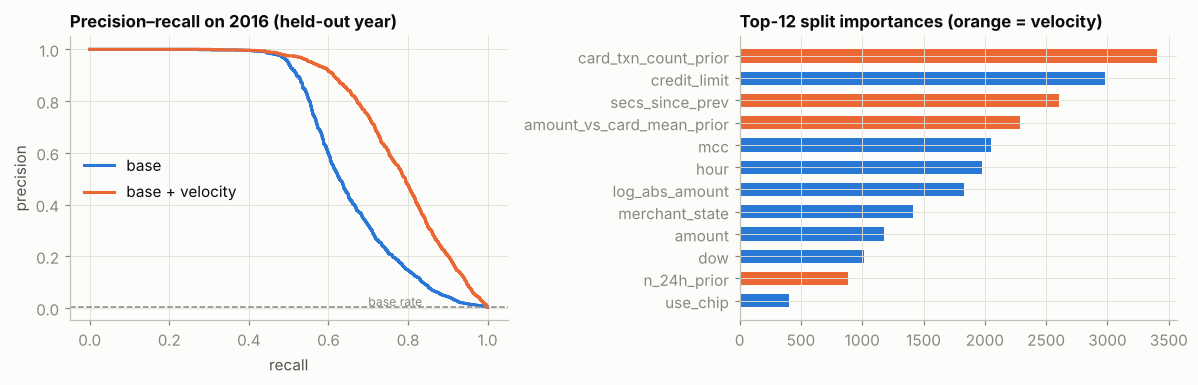

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for p, lab_, color in [(pte_base, "base", SERIES[0]), (pte_vel, "base + velocity", SERIES[1])]:
    pr, rc, _ = precision_recall_curve(y_te, p)
    ax.plot(rc, pr, lw=2, color=color, label=lab_)
ax.axhline(y_te.mean(), color=MUTED, ls="--", lw=1); ax.text(0.7, y_te.mean() * 3, "base rate", color=MUTED, fontsize=8)
ax.set_title("Precision–recall on 2016 (held-out year)"); ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.legend()
ax = axes[1]
imp = pd.Series(m_vel.feature_importances_, index=BASE + VELOCITY).sort_values(ascending=False).head(12)
colors = [SERIES[1] if f in VELOCITY else SERIES[0] for f in imp.index]
ax.barh(imp.index[::-1], imp.values[::-1], color=colors[::-1], height=0.6)
ax.set_title("Top-12 split importances (orange = velocity)")
plt.tight_layout()

The card's own history is worth more than any property of the transaction: the *first transaction at a merchant this client has never used*, *seconds since the previous swipe* and *how many in the last 24 h* carry the model. That is also the operational catch — these features need a low-latency feature store at authorisation time, which is an architecture decision (Block 1), not a modelling one.

## 5 · The operating point: capacity and cost, not 0.5

*Part B · Given model · package `expected_cost`; C3 asks you to own the cost assumptions.*

A probability threshold is a business decision with three costs. We choose it on the **validation months** (Nov–Dec 2015), then apply it unchanged to 2016:

- a **missed fraud** costs the transaction amount (the chargeback);
- every **alert** costs analyst time (`REVIEW_COST_EUR`);
- a **false alert that declines the payment** costs goodwill (`FALSE_DECLINE_COST_EUR`) — the number nobody can measure well, which is why it is a parameter and an ADR.

chosen threshold 0.05: 13 alerts/day on validation, cost €20,161 vs €90,058 with no model


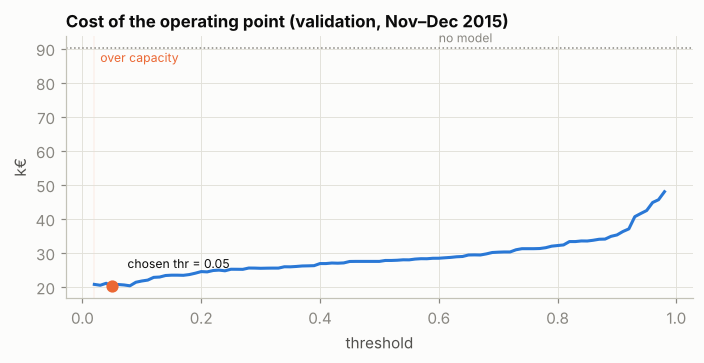

In [9]:
amt_va = tx.loc[va, "amount"].abs().values
amt_te = tx.loc[te, "amount"].abs().values
valid_days = (tx.loc[va, "date"].max() - tx.loc[va, "date"].min()).days + 1

def expected_cost(p, yv, amt, thr):
    alert = p >= thr
    missed = (~alert) & (yv == 1)
    false_alert = alert & (yv == 0)
    return (amt[missed].sum() + REVIEW_COST_EUR * alert.sum() + FALSE_DECLINE_COST_EUR * false_alert.sum(),
            alert.sum(), missed.sum(), false_alert.sum())

thresholds = np.linspace(0.02, 0.98, 97)
curve = pd.DataFrame([(t, *expected_cost(pva_vel, y_va.values, amt_va, t)) for t in thresholds],
                     columns=["thr", "cost", "alerts", "missed", "false_alerts"])
curve["alerts_per_day"] = curve.alerts / valid_days
feasible = curve[curve.alerts_per_day <= ANALYST_CAPACITY_PER_DAY]
best = feasible.loc[feasible.cost.idxmin()]
THR = float(best.thr)
no_model_cost = amt_va[y_va.values == 1].sum()   # let everything through

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(curve.thr, curve.cost / 1e3, lw=2, color=SERIES[0], label="expected cost (k€, validation)")
ax.axhline(no_model_cost / 1e3, color=MUTED, ls=":", lw=1); ax.text(0.6, no_model_cost / 1e3 * 1.02, "no model", color=MUTED, fontsize=8)
ax.axvspan(curve.thr.min(), feasible.thr.min(), color=SERIES[1], alpha=0.08)
ax.text(curve.thr.min() + 0.01, ax.get_ylim()[1] * 0.92, "over capacity", color=SERIES[1], fontsize=8)
ax.plot([THR], [best.cost / 1e3], "o", color=SERIES[1], ms=7)
ax.annotate(f"chosen thr = {THR:.2f}", (THR, best.cost / 1e3), xytext=(10, 12), textcoords="offset points", fontsize=8)
ax.set_title("Cost of the operating point (validation, Nov–Dec 2015)"); ax.set_xlabel("threshold"); ax.set_ylabel("k€")
plt.tight_layout()
print(f"chosen threshold {THR:.2f}: {best.alerts_per_day:.0f} alerts/day on validation, cost €{best.cost:,.0f} vs €{no_model_cost:,.0f} with no model")

,2016
fraud transactions in 2016,"2,448"
caught (alerted),"1,792"
missed,656
false alerts,994
alerts per day,8
days over capacity,2
fraud € prevented,"301,838"
fraud € missed,"71,282"
expected total cost €,"94,550"
cost with no model €,"373,120"


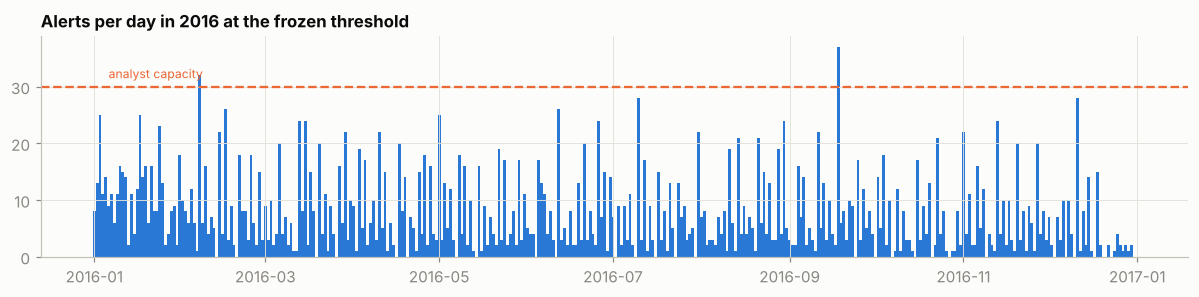

In [10]:
# Apply the frozen threshold to 2016 and report what the business would have seen
cost_te, alerts_te, missed_te, fa_te = expected_cost(pte_vel, y_te.values, amt_te, THR)
caught = alerts_te - fa_te
daily = pd.DataFrame({"date": tx.loc[te, "date"].dt.floor("D").values, "alert": (pte_vel >= THR)}).groupby("date").alert.sum()

fig, ax = plt.subplots(figsize=(11, 2.8))
ax.bar(daily.index, daily.values, width=1, color=SERIES[0])
ax.axhline(ANALYST_CAPACITY_PER_DAY, color=SERIES[1], lw=1.5, ls="--")
ax.text(daily.index[5], ANALYST_CAPACITY_PER_DAY * 1.05, "analyst capacity", color=SERIES[1], fontsize=8)
ax.set_title("Alerts per day in 2016 at the frozen threshold"); plt.tight_layout()

summary = pd.Series({
    "fraud transactions in 2016": int(y_te.sum()),
    "caught (alerted)": int(caught), "missed": int(missed_te), "false alerts": int(fa_te),
    "alerts per day": alerts_te / test_days, "days over capacity": int((daily > ANALYST_CAPACITY_PER_DAY).sum()),
    "fraud € prevented": amt_te[(pte_vel >= THR) & (y_te.values == 1)].sum(),
    "fraud € missed": amt_te[(pte_vel < THR) & (y_te.values == 1)].sum(),
    "expected total cost €": cost_te, "cost with no model €": amt_te[y_te.values == 1].sum(),
})
summary.to_frame("2016").style.format("{:,.0f}")

Read the last two rows together: the model's *value* is the gap between them, and it depends entirely on the two cost parameters you assumed. Vary them (task C3) before you believe the number. Also note the days over capacity — a threshold chosen on two calm months can flood the team in a bad week, which is why the alert count is a monitored metric (Session 04).

## 6 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Three things a careless version of this notebook would have done, each of which produces a better-looking number and a worse model.

**Trap 1 — attributes that fingerprint the entity.** Look at the importance chart above: `credit_limit` ranks near the top. It is known at authorisation time, so it passes the as-of test — but with ~3,500 cards it mostly acts as a *card identifier*, and the model learns *which cards* had fraud in 2015 (fraud recurs on the same cards in this simulator). The users table makes it worse: `credit_score`, `yearly_income`, `total_debt`, `current_age`, `gender` fingerprint the client. Watch where `gender` lands in the importance list — a protected attribute in a decision model is a regulatory problem regardless of accuracy — and then ask the question task C1 asks: how does the model do on cards it has never seen?

In [11]:
X["credit_score"] = tx.client_id.map(users.credit_score)
X["yearly_income"] = tx.client_id.map(users.yearly_income)
X["total_debt"] = tx.client_id.map(users.total_debt)
X["current_age"] = tx.client_id.map(users.current_age)
X["gender"] = tx.client_id.map(users.gender).astype("category")
X["card_on_dark_web"] = tx.card_id.map(cards.card_on_dark_web).map({"Yes": 1, "No": 0})
TRAPS = ["credit_score", "yearly_income", "total_debt", "current_age", "gender", "card_on_dark_web"]

m_trap, pva_trap, pte_trap, r_trap = fit_eval(BASE + VELOCITY + TRAPS, "base + velocity + client attributes ⚠")
# cards first seen in the test year: the fingerprint cannot help there
first_seen_card = tx.groupby("card_id").date.transform("min")
unseen = (first_seen_card[te] >= VALID_END).values
print(f"cards unseen in training: {unseen.sum():,} test rows, {int(y_te.values[unseen].sum())} fraud")
for name, p in [("base + velocity", pte_vel), ("with client attributes", pte_trap)]:
    if y_te.values[unseen].sum() > 0:
        print(f"  {name:24s} AUPRC on unseen cards {average_precision_score(y_te.values[unseen], p[unseen]):.3f} "
              f"vs all test rows {average_precision_score(y_te, p):.3f}")
trap_tbl = pd.DataFrame([r_vel, r_trap]).set_index("model")
display(trap_tbl.style.format({"AUPRC (test)": "{:.3f}", "ROC-AUC (test)": "{:.3f}", "precision@capacity": "{:.1%}",
                               "recall@capacity": "{:.1%}", "fit_s": "{:.0f}"}))
imp_trap = pd.Series(m_trap.feature_importances_, index=BASE + VELOCITY + TRAPS).sort_values(ascending=False)
print("rank of the trap features by split importance:",
      {f: int(np.flatnonzero(imp_trap.index == f)[0]) + 1 for f in TRAPS})
# training-set AUPRC: how much of the 'improvement' is memorisation?
p_tr_vel = m_vel.predict_proba(X.loc[tr, BASE + VELOCITY])[:, 1]
p_tr_trap = m_trap.predict_proba(X.loc[tr, BASE + VELOCITY + TRAPS])[:, 1]
print(f"train AUPRC  — base+velocity {average_precision_score(y_tr, p_tr_vel):.3f} · with client attributes {average_precision_score(y_tr, p_tr_trap):.3f}")
print(f"test  AUPRC  — base+velocity {r_vel['AUPRC (test)']:.3f} · with client attributes {r_trap['AUPRC (test)']:.3f}")

cards unseen in training: 15,264 test rows, 29 fraud


  base + velocity          AUPRC on unseen cards 0.771 vs all test rows 0.781


  with client attributes   AUPRC on unseen cards 0.777 vs all test rows 0.779


,AUPRC (test),ROC-AUC (test),precision@capacity,recall@capacity,fit_s
model,,,,,
base + velocity,0.781,0.994,20.1%,90.1%,46
base + velocity + client attributes ⚠,0.779,0.994,20.0%,89.7%,50


rank of the trap features by split importance: {'credit_score': 8, 'yearly_income': 2, 'total_debt': 6, 'current_age': 3, 'gender': 21, 'card_on_dark_web': 25}


train AUPRC  — base+velocity 1.000 · with client attributes 1.000
test  AUPRC  — base+velocity 0.781 · with client attributes 0.779


Read the three outputs together. The client attributes add **nothing** on 2016 (the model already fits 2015 perfectly without them, and it generalises to cards it never saw), yet `yearly_income` and `current_age` rank near the top by split count. Split importance measures how *often* a feature is used, not whether it helps — a tree will happily route decisions through income and age because they are convenient proxies. A model that reads a customer's income and age to decide whether to block their card is indefensible in front of a regulator or the customer, regardless of accuracy. Leave them out, and say so in the model card.

**Trap 2 — `card_on_dark_web`.** It looks like the perfect feature: a card known to be compromised. But the cards table is a snapshot with no date. Was the card on the dark web *before* this transaction, or was it listed *because* of the fraud you are trying to predict? Without an as-of timestamp, this is **target leakage of unknown size**, and the honest answer is to leave it out until the data provider can date it. Put that sentence in the model card.

**Trap 3 — the random split.** Shuffle the labelled 2015–2016 rows 70/30 and the same model reports a different number. Run it and compare with the forward-in-time result above; then decide which number you would put in front of the board.

**Trap 4 — the perfect feature.** Train on the first half of 2018 with `merchant_state` as the *only* feature and test on the second half. If a single column gives you a near-perfect model, you have not found a great feature; you have found how the simulator (or the labelling process) works. Real foreign-merchant fraud is not 88 % precise.

In [12]:
from sklearn.model_selection import train_test_split
idx = np.flatnonzero((is_lab & (tx.date < TEST_END)).values)
i_tr, i_te = train_test_split(idx, test_size=0.3, random_state=SEED, stratify=y.iloc[idx].astype(int))
cols = BASE + VELOCITY
m_rand = lgb.LGBMClassifier(**LGB_PARAMS).fit(X.iloc[i_tr][cols], y.iloc[i_tr].astype(int))
p_rand = m_rand.predict_proba(X.iloc[i_te][cols])[:, 1]
yr = y.iloc[i_te].astype(int).values
print(f"random 70/30 split (2015–16) · AUPRC {average_precision_score(yr, p_rand):.3f} · ROC-AUC {roc_auc_score(yr, p_rand):.3f}")
print(f"forward in time (2015 → 2016) · AUPRC {r_vel['AUPRC (test)']:.3f} · ROC-AUC {r_vel['ROC-AUC (test)']:.3f}")

# Trap 4: one column, 2018
h1 = is_lab & (tx.date >= "2018-01-01") & (tx.date < "2018-07-01")
h2 = is_lab & (tx.date >= "2018-07-01") & (tx.date < "2019-01-01")
m_perfect = lgb.LGBMClassifier(**LGB_PARAMS).fit(X.loc[h1, ["merchant_state"]], y[h1].astype(int))
p_perfect = m_perfect.predict_proba(X.loc[h2, ["merchant_state"]])[:, 1]
print(f"2018, merchant_state only   · AUPRC {average_precision_score(y[h2].astype(int), p_perfect):.3f} · "
      f"ROC-AUC {roc_auc_score(y[h2].astype(int), p_perfect):.3f}  ← suspect the data, not the feature")

random 70/30 split (2015–16) · AUPRC 0.859 · ROC-AUC 0.998
forward in time (2015 → 2016) · AUPRC 0.781 · ROC-AUC 0.994


2018, merchant_state only   · AUPRC 0.847 · ROC-AUC 0.978  ← suspect the data, not the feature


# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: the model goes blind, and nobody notices for months

*Part C · Productionise · what your monitoring plan must catch; reuse `psi`.*

Freeze the 2015 model and its threshold, and run it over 2017–2018 as if it were in production. Two things to watch, on two different clocks:

- **Now:** the inputs (amount, channel mix) and the *score distribution*, available the moment a transaction is scored. Session 04's PSI.
- **Later:** precision and recall, which only exist once the chargebacks arrive — typically 30–60 days after the transaction. We backfill them month by month, as the fraud team would have seen them.

The 33 % unlabelled rows are in the stream too: scored, alerted on, never evaluated. That is the normal condition of a production model.

,psi_amount,psi_score,online_share,alerts,alerts_per_day,fraud,recall,precision
month,,,,,,,,
2017-01,0.0,0.076,0.122,100,3.226,0.0,0.0,0.0
2017-04,0.0,0.093,0.120,70,2.333,0.0,0.0,0.0
2017-07,0.0,0.109,0.120,71,2.290,0.0,0.0,0.0
2017-10,0.0,0.125,0.120,60,1.935,0.0,0.0,0.0
2018-01,0.0,0.155,0.124,42,1.355,105.0,0.0,0.0
2018-04,0.0,0.163,0.120,40,1.333,173.0,0.0,0.0
2018-07,0.0,0.180,0.120,39,1.258,95.0,0.0,0.0
2018-10,0.0,0.209,0.120,41,1.323,126.0,0.0,0.0


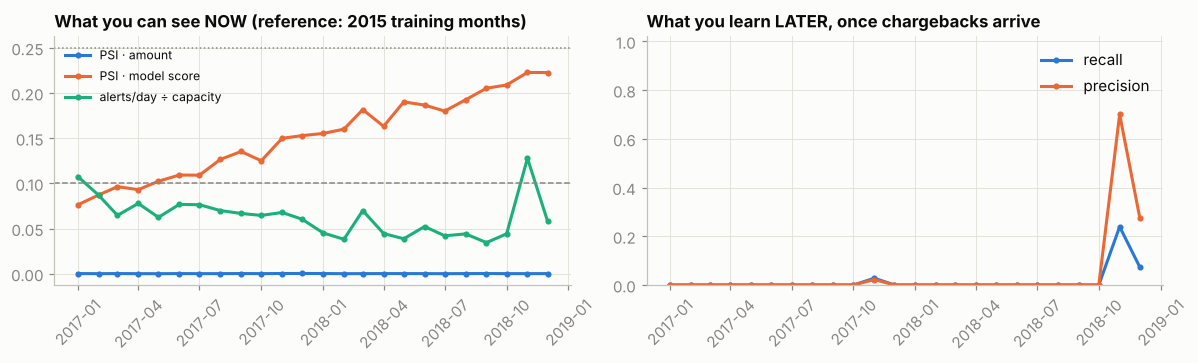

In [13]:
def psi(ref, cur, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref) + 1e-6
    c = np.histogram(cur, edges)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

stream = tx.date >= TEST_END                         # 2017–2018, labelled and unlabelled alike
p_stream = m_vel.predict_proba(X.loc[stream, BASE + VELOCITY])[:, 1]
ref_amount = X.loc[tr, "log_abs_amount"].values
ref_score = m_vel.predict_proba(X.loc[tr, BASE + VELOCITY])[:, 1]
sdf = pd.DataFrame({"month": tx.loc[stream, "date"].dt.to_period("M").values,
                    "amount": X.loc[stream, "log_abs_amount"].values, "score": p_stream,
                    "online": (tx.loc[stream, "use_chip"] == "Online Transaction").values,
                    "y": y[stream].values, "alert": p_stream >= THR})
sdf["labelled"] = sdf.y.notna()
days_in_month = sdf.groupby("month").size().index.to_timestamp().days_in_month
now = sdf.groupby("month").agg(psi_amount=("amount", lambda s: psi(ref_amount, s.values)),
                               psi_score=("score", lambda s: psi(ref_score, s.values)),
                               online_share=("online", "mean"), alerts=("alert", "sum"))
now["alerts_per_day"] = now.alerts / days_in_month.values
lab_s = sdf[sdf.labelled].assign(y=lambda d: d.y.astype(int))
later = lab_s.groupby("month").apply(lambda d: pd.Series({
    "fraud": int(d.y.sum()),
    "recall": ((d.alert) & (d.y == 1)).sum() / max(d.y.sum(), 1),
    "precision": ((d.alert) & (d.y == 1)).sum() / max(d.alert.sum(), 1)}), include_groups=False)
monitor = now.join(later)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
t_ = monitor.index.to_timestamp()
ax.plot(t_, monitor.psi_amount, "-o", ms=3, lw=2, color=SERIES[0], label="PSI · amount")
ax.plot(t_, monitor.psi_score, "-o", ms=3, lw=2, color=SERIES[1], label="PSI · model score")
ax.plot(t_, monitor.alerts_per_day / ANALYST_CAPACITY_PER_DAY, "-o", ms=3, lw=2, color=SERIES[2], label="alerts/day ÷ capacity")
ax.axhline(0.10, color=MUTED, ls="--", lw=1); ax.axhline(0.25, color=MUTED, ls=":", lw=1)
ax.set_title("What you can see NOW (reference: 2015 training months)"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=45)
ax = axes[1]
ax.plot(t_, monitor.recall, "-o", ms=3, lw=2, color=SERIES[0], label="recall")
ax.plot(t_, monitor.precision, "-o", ms=3, lw=2, color=SERIES[1], label="precision")
ax.set_ylim(0, 1.02)
ax.set_title("What you learn LATER, once chargebacks arrive"); ax.legend(); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
monitor.iloc[::3].round(3)

This is Session 04's silent failure, end to end. Through 2017–2018 the amount distribution does not move at all, the alert queue keeps arriving (smaller, but nobody is alarmed by *fewer* alerts), and the service is healthy. Meanwhile recall has gone to zero: the simulator moved fraud from online to chip-at-a-foreign-merchant, and a model that learned "online" keeps alerting on online. The one early signal is the **score PSI**, which creeps into the warning band from mid-2017 — ambiguous on its own (a changing channel mix would do the same), but it is the signal a monitoring plan should have turned into a question. The metric that settles it, recall, cannot be computed until the labels arrive, weeks later.

Three consequences for your monitoring plan (task C5): you need a *label-delay-aware* accuracy backfill with an alert on it; you need a drift signal that looks at **where fraud is confirmed**, not only at the inputs; and you need a retraining trigger that fires on the backfilled recall, with a rollback path through the registry alias (Session 06).

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The ten principles every project covers, updated with what this notebook measured.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/` package with `get_raw` and `load_window` (5.57 M rows, 753 MB in memory), `build_features` (19 base and velocity features), `fit_eval`, `precision_at_k` and `expected_cost`; a scoring endpoint called per authorised transaction; the velocity features served from a low-latency feature store |
| Monitoring (S04) | Now: score PSI against the 2015 training months (0.076 in Jan 2017, 0.209 in Oct 2018; warning at 0.10, alarm at 0.25), amount PSI (0.00 throughout), online share (0.12), alerts a day against capacity 30 (8 a day in 2016, 1.3–3.2 in the 2017–2018 months shown in Section 7: a fall is a signal too). Later: recall and precision backfilled once chargebacks arrive, 30–60 days after the transaction |
| CI/CD gate (S05) | Precision and recall at capacity (k = 10,980 over 2016): 20.1 % and 90.1 % today, AUPRC 0.781; fail below the base-only model (AUPRC 0.654, precision 17.4 %). As-of test on `build_features`; leakage test that rejects the client attributes and `card_on_dark_web` |
| MLflow tracking and registry (S06) | Windows (train Jan–Oct 2015, validation Nov–Dec 2015, test 2016), the 19 features with the excluded ones named, `LGB_PARAMS`, `SEED`, threshold 0.05, `REVIEW_COST_EUR` 3, `FALSE_DECLINE_COST_EUR` 15, capacity 30; `champion` alias as the rollback path |
| Offline / online training and serving | Online scoring in the authorisation path; offline training on labelled rows only, with the 33 % unlabelled rows scored and never trained on; retraining triggered by backfilled recall, not by the calendar alone |
| Data and model drift | Concept drift with no input drift: online fraud is 85–86 % of fraud in 2015–2016 and 0–5 % in 2017–2018, where 94–100 % is at a foreign merchant. At the frozen threshold recall is 0 every month of 2017–2018 while amount PSI stays at 0.00 |
| Knowledge base and context (S07–S09) | The 109 MCC codes and the merchant hierarchy (74,831 merchants) as a small ontology; one definition of a *decline* shared by the switch, the case tool and the chargeback process |
| GenAI and context engineering (S10–S11) | Analyst case note and customer-facing decline explanation for the top-50 alerts, grounded only in the model's features and SHAP values; evaluated for factuality and tone |
| Governance | Synthetic, Apache-2.0; card numbers, CVVs and expiry dates dropped on load; user attributes treated as sensitive and kept out of the model (they add nothing: AUPRC 0.779 with them, 0.781 without); `card_on_dark_web` undated; EU AI Act and GDPR Article 22 position |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S2**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** Remove the leaking and protected features, decide what to do about `credit_limit` (evaluate on cards unseen in training before you decide), state the as-of rule as a test (`tests/test_features.py` must fail if any feature uses a future row), and report the honest 2016 numbers.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `FALSE_DECLINE_COST_EUR` over a plausible range and `ANALYST_CAPACITY_PER_DAY` over 10–100; show how the chosen threshold and the 2016 cost move; write the ADR that records the assumption you recommend and who signed it off.
- **C4 — Package and gate.** Move feature construction into `src/`, add tests, and add a CI quality gate on precision@capacity against a frozen evaluation month (Session 05).
- **C5 — Register, document, monitor.** Track runs in MLflow, register the chosen model with a `champion` alias, write the model card (synthetic provenance, the regime artefact, the undated static tables, the cost assumptions), and a one-page monitoring plan that states the label-delay window, the backfilled-recall alert and the retraining trigger that would have caught 2017 (Sessions 04 and 06).

### Extension

- **E1 — Fairness check without protected features.** The model must not use `gender` or age, but its *errors* may still differ by group. Measure false-alert rate and missed-fraud rate by gender and by age band on 2016, and write the two sentences a regulator would read.
- **E2 — Is the score a probability?** Analysts and the cost model assume it is. Check the given model's calibration on validation and on 2017 (a reliability diagram; no refitting), state in the model card what the cost model may and may not assume, and add calibration error to the monitoring plan.
- **E3 — Unseen merchants in production.** `merchant_id` has 75 k levels and new merchants appear every month. Measure the share of 2017–2018 transactions at merchants absent from training, how the given model scores them, and add that share to the monitoring plan with a threshold.
- **E4 — Regulatory position.** Where does a card-fraud model sit under the EU AI Act (check Annex III's creditworthiness item and its fraud-detection carve-out) and under GDPR Article 22 (automated decisions)? What does "human review of a decline" have to mean operationally?

### Stretch

- **S1 — Online features.** Sketch the feature-serving architecture: which features are computed in the authorisation path (latency budget in milliseconds), which in a streaming job, which nightly. Cost it (Session 11).
- **S2 — Explain a decline.** For the top-50 alerts, produce an analyst case note and a customer-facing explanation generated by an LLM grounded only on the model's features and SHAP values (Session 10); evaluate for factuality and tone (Session 11).
- **S3 — Retraining policy.** Simulate monthly retraining through 2017–2018 with a 45-day label delay. How many months of blindness does it leave, what does it cost, and would a drift-triggered retrain have done better than a calendar one?

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed; card secrets never loaded
- [ ] `README.md` states the window (`WINDOW_START`, `WINDOW_END`), the split dates, the stream period and how to obtain the data (Kaggle, Apache-2.0)
- [ ] Forward-in-time evaluation only; traps removed; as-of test in the suite
- [ ] Operating point chosen from cost and capacity, with the ADR
- [ ] CI pipeline with tests and the precision@capacity gate; registered model with model card; monitoring plan with label delay
- [ ] One-page stakeholder recommendation (value, cost assumptions, fairness check, regulatory position)
- [ ] Required tasks done: C1–C5, E1–E4 and S2
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `lightgbm`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`).
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 4 (training data: sampling, class imbalance), Ch. 5 (feature engineering: leakage), Ch. 8 (distribution shifts and monitoring).
- Kaufman, S., Rosset, S., Perlich, C. (2012). *Leakage in Data Mining: Formulation, Detection, and Avoidance.* ACM TKDD.
- Mitchell, M. et al. (2019). *Model Cards for Model Reporting.* FAT*.

In [14]:
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

notebook finished · total wall time 334s
